# Encontro 8. Erro de amostragem, tamanho da amostra e instrumentos de coleta

**Disciplina:** Métodos e Técnicas de Pesquisa Quantitativa, Administração/UFMA
**Docente:** Prof. Dr. Tadeu Gomes Teixeira

> **O que você vai fazer hoje**
> 1. **Executar** as células de cima para baixo.
> 2. **Mudar valores** no bloco de configuração: a margem de erro, o nível de confiança
>    e o tamanho do cadastro. O notebook vira um **simulador de tamanho de amostra**.
> 3. **Escrever** a frase do tamanho da amostra e responder as três perguntas do fim.
>
> Você não vai escrever código. Se algo não funcionar, **chame o professor**.

---

## Painel do encontro

No encontro 7 a pergunta foi: *se eu sortear mil vezes, como as estimativas se
distribuem?* Hoje a pergunta é a do pesquisador que vai a campo: **quantos casos eu
preciso sortear para errar no máximo tanto, com tanta confiança?**

| Item | Valor |
|---|---|
| **Base 1** | ANP, Série Histórica de Preços de Combustíveis (SHPC): o **cadastro de 236 postos** do Maranhão, gasolina comum, 2025 |
| **O que é cada linha** | Um posto, com CNPJ, município, bandeira e o preço médio da gasolina no ano (R\$ por litro), a média das coletas do ano |
| **Média e desvio da população** | **R\$ 5,9744** e **R\$ 0,3755** (os mesmos dos encontros 6 e 7) |
| **Base 2** | Receita Federal, base CNPJ, tabela de municípios: **5.572 linhas**, o exemplo de cadastro grande |
| **Base 3** | Respostas a uma escala Likert de 6 itens, de **200 gestores SIMULADOS**. Não são dados reais: foram gerados por código, com semente fixa, para ensinar o alfa de Cronbach |

**Glossário do dia**

| Termo | Em uma linha |
|---|---|
| **Erro de amostragem** | A diferença entre a estimativa da amostra e o valor verdadeiro da população |
| **Viés** | Erro sistemático: empurra a estimativa sempre para o mesmo lado e não diminui com n |
| **Erro padrão (EP)** | O quanto a estimativa costuma variar de amostra para amostra: s ÷ √n |
| **Nível de confiança** | A proporção de amostras, entre todas as possíveis, cujo erro fica dentro da margem |
| **Margem de erro (E)** | O erro máximo aceito, ao nível de confiança escolhido: E = z × EP |
| **Tamanho da amostra (n)** | O número de casos que entrega a margem pedida; sai da fórmula, não de porcentagem |
| **Correção para população finita** | O ajuste que reduz o n quando a amostra é uma fatia grande do cadastro |
| **Alfa de Cronbach** | O quanto os itens de uma escala “andam juntos”; vai de 0 a 1, com 0,7 como piso usual |

> **A regra do semestre:** a IA explica, o código calcula e você confere e escreve.

## Bloco de configuração

**O único lugar do notebook onde se mexe em código.** Os valores abaixo são os do slide.
Depois de executar o notebook inteiro uma vez, volte aqui, mude **um** valor de cada vez
e execute de novo: as células recalculam o tamanho da amostra e a simulação confere se a
margem prevista se cumpre.

> O `conferir` compara com os números do slide, que usam os valores originais. Se você
> mudar a configuração, ele vai mostrar `[X ]`, e isso é esperado: o número mudou porque
> você mudou a pergunta.

In [1]:
CONFIANCA   = 0.95   # nível de confiança: 0.90, 0.95 ou 0.99
MARGEM      = 0.05   # margem de erro da MÉDIA, em R$ por litro (0.05 = 5 centavos)
MARGEM_PROP = 0.05   # margem de erro da PROPORÇÃO (0.05 = 5 pontos percentuais)
N_POPULACAO = 5572   # tamanho do cadastro grande (5572 = municípios da Receita)
N_VEZES     = 1000   # quantas amostras sortear na verificação por simulação

print(f"Confiança {CONFIANCA:.0%} | margem da média R$ {MARGEM:.2f} | "
      f"margem da proporção {MARGEM_PROP * 100:.0f} p.p.")
print(f"Cadastro grande: {N_POPULACAO} | simulação com {N_VEZES} amostras")

Confiança 95% | margem da média R$ 0.05 | margem da proporção 5 p.p.
Cadastro grande: 5572 | simulação com 1000 amostras


## Utilitários da disciplina

`conferir` compara o seu resultado com o número do slide. **Não precisa alterá-la.**

In [2]:

# =====================================================================
#  UTILITARIOS DA DISCIPLINA - nao precisa alterar nada daqui para baixo
#  estas duas funcoes sao usadas pelas celulas do encontro. Se voce nao
#  sabe o que elas fazem, tudo bem: nao mexa. Voce so precisa executar.
# =====================================================================

def conferir(descricao, obtido, esperado, tolerancia=0.005, unidade="%"):
    """Confere o resultado calculado contra o valor ja resolvido no slide.

    Chame assim:  conferir("taxa de sobrevivencia do setor X", obtido, 0.412)

    O 'esperado' e o numero que ja estava escrito no slide, resolvido a mao
    pelo professor. Se aparecer [ok], o seu calculo esta certo. Se aparecer
    [X], confira a base, o filtro e a coluna que voce usou.
    """
    try:
        dif = abs(float(obtido) - float(esperado))
    except (TypeError, ValueError):
        print("  [X ] nao deu para comparar: obtido = %r" % (obtido,))
        return
    num = lambda v: ("%.*f%s" % (2, v, unidade)) if unidade else ("%.4f" % v)
    if dif <= tolerancia:
        print("  [ok] %-54s obtido %-9s esperado %s"
              % (descricao[:54], num(float(obtido)), num(float(esperado))))
    else:
        print("  [X ] %-54s obtido %-9s esperado %-9s dif %s"
              % (descricao[:54], num(float(obtido)), num(float(esperado)), num(dif)))


def cartao(df, coluna, nome_base="base"):
    """Imprime o contexto que voce precisa colar no assistente de IA.

    Chame assim:  cartao(dados, "porte")

    Copie a saida inteira e cole no pedido. E isso que impede a IA de
    inventar numero: ela so pode usar o que esta escrito no cartao.
    """
    print("=== CARTAO DE CONTEXTO (copie tudo daqui para o assistente) ===")
    print("base: %s" % nome_base)
    print("linhas x colunas: %d x %d" % df.shape)
    print("colunas e seu significado:")
    for c in df.columns:
        print("   - %s (%s)" % (c, df[c].dtype))
    if coluna in df.columns:
        print("valores unicos de '%s': %s"
              % (coluna, sorted(map(str, df[coluna].dropna().unique()))[:25]))
    print("=== fim do cartao ===")


print("Utilitarios carregados: conferir() e cartao() estao prontas para uso.")


Utilitarios carregados: conferir() e cartao() estao prontas para uso.


## Seção 1. Os dois cadastros

Um **cadastro** é a lista de onde se sorteia. Hoje há dois, de tamanhos muito diferentes, e
essa diferença é de propósito: ela vai mostrar que **o tamanho da amostra quase não depende
do tamanho da população**.

| Cadastro | Tamanho | Para que serve hoje |
|---|---|---|
| Postos de gasolina do Maranhão (ANP) | 236 | O valor verdadeiro é **conhecido**: dá para sortear e conferir se a margem se cumpre |
| Municípios do Brasil (Receita Federal) | 5.572 | O exemplo de cadastro grande, para o cálculo do n de uma proporção |

Cada cadastro tem uma **CÉLULA A**, que baixa os dados, e uma **CÉLULA B** de contingência,
que só se usa se o professor mandar.

In [3]:
# ================= CÉLULA A1: o cadastro de postos (ANP) =================
# O mesmo cadastro dos encontros 6 e 7: um registro por posto, com o preço médio do ano.
# Se esta célula falhar, peça ao professor para usar a CÉLULA B1.

import pandas as pd

URL_ANP = ("https://raw.githubusercontent.com/tadeugomes/"
           "metodos-pesquisa-quantitativa/main/dados/anp_precos_revenda_ma_2025.csv")

try:
    anp = pd.read_csv(URL_ANP)
except Exception:
    # caminho local do repositório, usado na geração do notebook
    anp = pd.read_csv("dados/anp_precos_revenda_ma_2025.csv")

gas = anp[anp["produto"] == "GASOLINA"].dropna(subset=["valor_venda"])
# um posto por linha: o preço é a média de todas as coletas do ano, e a bandeira, a
# mais frequente no ano (alguns postos trocam de bandeira)
cadastro = (gas.groupby(["cnpj_da_revenda", "municipio"], as_index=False)
               .agg(bandeira=("bandeira", lambda b: b.mode().iloc[0]),
                    preco_medio=("valor_venda", "mean")))

populacao = cadastro["preco_medio"]
N = len(cadastro)

print(f"Cadastro de postos: N = {N} postos, em {cadastro['municipio'].nunique()} municípios")
print(f"  média da população (o parâmetro) = R$ {populacao.mean():.4f}")
print(f"  desvio padrão da população       = R$ {populacao.std():.4f}")
print()
conferir("postos no cadastro", N, 236, tolerancia=0, unidade=" postos")
conferir("média da população (R$ por litro)", populacao.mean(), 5.9744,
         tolerancia=0.0001, unidade="")
conferir("desvio padrão da população (R$ por litro)", populacao.std(), 0.3755,
         tolerancia=0.0001, unidade="")

Cadastro de postos: N = 236 postos, em 11 municípios
  média da população (o parâmetro) = R$ 5.9744
  desvio padrão da população       = R$ 0.3755

  [ok] postos no cadastro                                     obtido 236.00 postos esperado 236.00 postos
  [ok] média da população (R$ por litro)                      obtido 5.9744    esperado 5.9744
  [ok] desvio padrão da população (R$ por litro)              obtido 0.3755    esperado 0.3755


In [ ]:
# ================= CÉLULA B1: CONTINGÊNCIA, leia antes =================
# NÃO EXECUTE AGORA. Só se a CÉLULA A1 falhar e o professor mandar, depois de fazer
# upload do arquivo dados/anp_precos_revenda_ma_2025.csv (ícone de pasta, à esquerda).

import pandas as pd

anp = pd.read_csv("anp_precos_revenda_ma_2025.csv")
gas = anp[anp["produto"] == "GASOLINA"].dropna(subset=["valor_venda"])
# um posto por linha: o preço é a média de todas as coletas do ano, e a bandeira, a
# mais frequente no ano (alguns postos trocam de bandeira)
cadastro = (gas.groupby(["cnpj_da_revenda", "municipio"], as_index=False)
               .agg(bandeira=("bandeira", lambda b: b.mode().iloc[0]),
                    preco_medio=("valor_venda", "mean")))
populacao = cadastro["preco_medio"]
N = len(cadastro)
print(f"Cadastro montado do arquivo local: N = {N} postos")

In [4]:
# ================= CÉLULA A2: o cadastro grande (Receita Federal) =================
# A tabela de municípios da base CNPJ, baixada da Receita Federal. O endereço aceita
# um "token" público de compartilhamento, sem cadastro (dados/FONTES.md, seção 3.5).
# Se aparecer "could not resolve host", 401 ou tempo esgotado, use a CÉLULA B2.

import io
import zipfile

import requests

URL_RF = "https://arquivos.receitafederal.gov.br/public.php/webdav/2026-09/Municipios.zip"
resposta = requests.get(URL_RF, auth=("YggdBLfdninEJX9", ""), timeout=300)

with zipfile.ZipFile(io.BytesIO(resposta.content)) as pacote:
    with pacote.open(pacote.namelist()[0]) as arquivo:
        municipios = pd.read_csv(arquivo, sep=";", encoding="latin-1", dtype=str,
                                 names=["codigo", "nome"])

print(f"Cadastro de municípios da Receita Federal: {len(municipios)} linhas")
print("Repare: o código é o identificador, e o nome (sem acento) é só o rótulo.")
print(municipios[municipios["nome"] == "SAO LUIS"].to_string(index=False))
print()
conferir("municípios no cadastro da Receita", len(municipios), 5572,
         tolerancia=0, unidade=" munic.")

Cadastro de municípios da Receita Federal: 5572 linhas
Repare: o código é o identificador, e o nome (sem acento) é só o rótulo.
codigo     nome
  0921 SAO LUIS

  [ok] municípios no cadastro da Receita                      obtido 5572.00 munic. esperado 5572.00 munic.


In [ ]:
# ================= CÉLULA B2: CONTINGÊNCIA, leia antes =================
# NÃO EXECUTE AGORA. Só se a CÉLULA A2 falhar e o professor mandar, depois de fazer
# upload do arquivo dados/rf_cnpj_municipios.csv.

import pandas as pd

municipios = pd.read_csv("rf_cnpj_municipios.csv", dtype=str)
print(f"Cadastro de municípios do arquivo local: {len(municipios)} linhas")

## Parte 2 · Estatística: margem de erro e tamanho da amostra

**A pergunta do bloco.** *Quantos postos eu preciso visitar para estimar o preço médio da
gasolina no Maranhão com erro de, no máximo, 5 centavos?*

**A ideia.** O erro padrão do encontro 7 diz quanto a estimativa varia. O **nível de
confiança** diz quantas amostras, entre todas as possíveis, se quer cobrir. E a **margem de
erro** junta as duas coisas. Se a margem depende de n, dá para fazer a conta ao contrário:
**escolher a margem e descobrir o n**.

$$EP = \frac{s}{\sqrt{n}} \qquad\qquad E = z \times EP$$

$$n_0 = \left(\frac{z \times s}{E}\right)^2 \quad \text{(média)} \qquad\qquad
n_0 = \frac{z^2 \times p\,(1-p)}{E^2} \quad \text{(proporção)}$$

$$n = \frac{n_0}{1 + \dfrac{n_0 - 1}{N}} \quad \text{(correção para população finita)}$$

* $s$ é o desvio padrão da variável; $n$ é o tamanho da amostra; $N$ é o tamanho do cadastro
* $z$ é o número de erros padrão que o nível de confiança exige: 1,645 (90%), 1,960 (95%), 2,576 (99%)
* $E$ é a margem de erro: em R\$ por litro para a média, em proporção para a proporção
* $p$ é a proporção esperada; sem informação prévia, usa-se **p = 0,5**, o caso que exige o maior n

**Em linguagem corrente:** escolha a margem que você aceita e a confiança que você quer; a
fórmula devolve quantos casos sortear. Se o n sair perto do tamanho do cadastro, a correção
para população finita reduz o número.

**Quando usar e quando não usar**

| | |
|---|---|
| **Use** | Para planejar uma coleta **por sorteio**, antes de ir a campo, e para declarar a margem no relatório |
| **Não use** | Para dar margem de erro a amostra por conveniência. A fórmula supõe sorteio; sem ele, o erro que importa é o **viés**, e nenhuma fórmula o mede |

### 1. Do erro padrão à margem de erro

O encontro 7 terminou com uma pergunta em aberto: a largura das mil médias (R\$ 0,0482)
saiu **9% menor** que a prevista pela fórmula (R\$ 0,0531), e por isso 72,1% e 97,1% das
médias caíram a 1 e a 2 erros padrão, contra 68,3% e 95,4% da regra. A célula abaixo
transforma o erro padrão em margem de erro e resolve o mistério nas duas réguas: a do erro
padrão, que era a pergunta do encontro 7, e a da margem, que é a de hoje.

In [5]:
# Do erro padrão à margem de erro: o exemplo do encontro 7 (amostras de 50 postos).
import numpy as np
from scipy.stats import norm

n_e7 = 50
s = populacao.std()
z95 = norm.ppf(0.975)                       # 1,96: o z de 95% de confiança

ep = s / n_e7 ** 0.5                        # erro padrão
fpc = ((N - n_e7) / (N - 1)) ** 0.5         # correção para população finita
margem_e7 = z95 * ep                        # margem de erro, sem correção
margem_e7_corrigida = z95 * ep * fpc        # margem de erro, com correção

medias_50 = np.array([populacao.sample(n=n_e7, random_state=k).mean()
                      for k in range(N_VEZES)])
erros_50 = np.abs(medias_50 - populacao.mean())

print(f"erro padrão (s ÷ √50) ..................... R$ {ep:.4f}")
print(f"margem a 95% (1,96 × EP) .................. R$ {margem_e7:.4f}")
print(f"fator de correção √((N − n) ÷ (N − 1)) .... {fpc:.4f}")
print(f"margem a 95%, com a correção .............. R$ {margem_e7_corrigida:.4f}")
print()
print(f"Das {N_VEZES} amostras de 50 postos:")
print(f"  {(erros_50 <= margem_e7).mean() * 100:.1f}% erraram menos que R$ {margem_e7:.4f}")
print(f"  {(erros_50 <= margem_e7_corrigida).mean() * 100:.1f}% erraram menos que "
      f"R$ {margem_e7_corrigida:.4f}   (a promessa era 95%)")
print()
print()
ep_corrigido = ep * fpc
largura = medias_50.std()
dentro_ep = lambda k, e: (erros_50 < k * e).mean() * 100
print("O mistério do encontro 7, na régua do erro padrão:")
print(f"  largura observada das {N_VEZES} médias ........ R$ {largura:.4f}")
compara = lambda e: (f"a observada é {abs(1 - largura / e) * 100:.0f}% "
                     + ("menor" if largura < e else "maior"))
print(f"  erro padrão sem correção (s ÷ √50) ...... R$ {ep:.4f}   ({compara(ep)})")
print(f"  erro padrão com correção (× {fpc:.4f}) ... R$ {ep_corrigido:.4f}   ({compara(ep_corrigido)})")
print(f"  médias a 1 e a 2 EP, sem correção ....... {dentro_ep(1, ep):.1f}% e {dentro_ep(2, ep):.1f}%")
print(f"  médias a 1 e a 2 EP, com correção ....... {dentro_ep(1, ep_corrigido):.1f}% e "
      f"{dentro_ep(2, ep_corrigido):.1f}%   (a regra: 68,3% e 95,4%)")
print()
print("A amostra de 50 é 21% do cadastro: é por isso que a largura do encontro 7 saiu")
print("menor que a fórmula previa. A correção para população finita explica a diferença.")
print()
conferir("erro padrão com correção finita, n = 50 (R$)", ep_corrigido, 0.0472,
         tolerancia=0.0001, unidade="")
conferir("médias a 1 EP corrigido (%)", dentro_ep(1, ep_corrigido), 66.5, tolerancia=0.05, unidade="%")
conferir("médias a 2 EP corrigidos (%)", dentro_ep(2, ep_corrigido), 95.7, tolerancia=0.05, unidade="%")
conferir("erro padrão, n = 50 (R$)", ep, 0.0531, tolerancia=0.0001, unidade="")
conferir("margem de erro a 95%, n = 50 (R$)", margem_e7, 0.1041, tolerancia=0.0001, unidade="")
conferir("margem com correção finita, n = 50 (R$)", margem_e7_corrigida, 0.0926,
         tolerancia=0.0001, unidade="")

erro padrão (s ÷ √50) ..................... R$ 0.0531
margem a 95% (1,96 × EP) .................. R$ 0.1041
fator de correção √((N − n) ÷ (N − 1)) .... 0.8897
margem a 95%, com a correção .............. R$ 0.0926

Das 1000 amostras de 50 postos:
  96.9% erraram menos que R$ 0.1041
  95.3% erraram menos que R$ 0.0926   (a promessa era 95%)


O mistério do encontro 7, na régua do erro padrão:
  largura observada das 1000 médias ........ R$ 0.0482
  erro padrão sem correção (s ÷ √50) ...... R$ 0.0531   (a observada é 9% menor)
  erro padrão com correção (× 0.8897) ... R$ 0.0472   (a observada é 2% maior)
  médias a 1 e a 2 EP, sem correção ....... 72.1% e 97.1%
  médias a 1 e a 2 EP, com correção ....... 66.5% e 95.7%   (a regra: 68,3% e 95,4%)

A amostra de 50 é 21% do cadastro: é por isso que a largura do encontro 7 saiu
menor que a fórmula previa. A correção para população finita explica a diferença.

  [ok] erro padrão com correção finita, n = 50 (R$)           obtido 0.0472    espera

> **Dica de estudo**: a correção para população finita só importa quando a amostra é uma fatia grande do cadastro (acima de uns 5%). Com 50 de 236 (21%), ela leva o erro padrão de 0,0531 para 0,0472 e a margem de 0,1041 para 0,0926.

### 2. O nível de confiança vira um número

Confiança de 95% quer dizer: **de cada 100 amostras sorteadas, 95 ficam a menos de z erros
padrão do valor verdadeiro**. O z é a régua do escore z do encontro 4.

In [6]:
# O nível de confiança vira um número: o z.
tabela_z = pd.DataFrame({"confiança": ["90%", "95%", "99%"],
                         "z": norm.ppf([0.95, 0.975, 0.995]).round(3)})
print(tabela_z.to_string(index=False))
print()

z = norm.ppf(1 - (1 - CONFIANCA) / 2)
print(f"Na sua configuração: confiança de {CONFIANCA:.0%}  →  z = {z:.3f}")
print("Mais confiança exige um z maior e, com ele, uma amostra maior.")
print()
conferir("z para 95% de confiança", z, 1.960, tolerancia=0.001, unidade="")

confiança     z
      90% 1.645
      95% 1.960
      99% 2.576

Na sua configuração: confiança de 95%  →  z = 1.960
Mais confiança exige um z maior e, com ele, uma amostra maior.

  [ok] z para 95% de confiança                                obtido 1.9600    esperado 1.9600


### 3. O tamanho da amostra para a média

A conta ao contrário: em vez de partir do n e chegar à margem, parte-se da margem
(R\$ 0,05) e chega-se ao n.

In [7]:
# O tamanho da amostra para estimar a MÉDIA, passo a passo.
n0_media = (z * s / MARGEM) ** 2                       # passo 1: sem correção
n_media = n0_media / (1 + (n0_media - 1) / N)          # passo 2: com a correção para N
n_media_final = int(np.ceil(n_media))                  # passo 3: arredonda PARA CIMA

print(f"Pergunta: estimar o preço médio com margem de R$ {MARGEM:.2f}, a {CONFIANCA:.0%}")
print()
print(f"  passo 1: n0 = ({z:.3f} × {s:.4f} ÷ {MARGEM:.2f})² = {n0_media:.1f}"
      f"  →  {int(np.ceil(n0_media))} postos")
print(f"  passo 2: n  = {n0_media:.1f} ÷ (1 + {n0_media - 1:.1f} ÷ {N}) = {n_media:.1f}")
print(f"  passo 3: arredondando para cima: n = {n_media_final} postos "
      f"({n_media_final / N:.0%} do cadastro)")
print()
print(f"Sem a correção, a fórmula pediria {int(np.ceil(n0_media))} postos; com ela, "
      f"{n_media_final} bastam, porque o cadastro inteiro tem só {N}.")
print()
conferir("n sem correção (média, ±R$ 0,05, 95%)", np.ceil(n0_media), 217,
         tolerancia=0, unidade=" postos")
conferir("n com correção para N = 236", n_media_final, 114, tolerancia=0, unidade=" postos")

Pergunta: estimar o preço médio com margem de R$ 0.05, a 95%

  passo 1: n0 = (1.960 × 0.3755 ÷ 0.05)² = 216.6  →  217 postos
  passo 2: n  = 216.6 ÷ (1 + 215.6 ÷ 236) = 113.2
  passo 3: arredondando para cima: n = 114 postos (48% do cadastro)

Sem a correção, a fórmula pediria 217 postos; com ela, 114 bastam, porque o cadastro inteiro tem só 236.

  [ok] n sem correção (média, ±R$ 0,05, 95%)                  obtido 217.00 postos esperado 217.00 postos
  [ok] n com correção para N = 236                            obtido 114.00 postos esperado 114.00 postos


### 4. A verificação por simulação

Aqui está a vantagem de um cadastro cujo valor verdadeiro é conhecido: dá para **sortear
mil vezes** com o n calculado e contar quantas amostras ficaram dentro da margem.

In [8]:
# A verificação: a margem prometida se cumpre? Sorteamos N_VEZES amostras de n postos.
estimativas = np.array([populacao.sample(n=n_media_final, random_state=k).mean()
                        for k in range(N_VEZES)])
erros = estimativas - populacao.mean()
dentro = (np.abs(erros) <= MARGEM).mean() * 100

print(f"{N_VEZES} amostras de {n_media_final} postos")
print(f"  centro das estimativas ............ R$ {estimativas.mean():.4f} "
      f"(valor verdadeiro R$ {populacao.mean():.4f})")
print(f"  erro máximo aceito (a margem) ..... R$ {MARGEM:.2f}")
print(f"  amostras dentro da margem ......... {dentro:.1f}%")
print(f"  o que a confiança prometia ........ {CONFIANCA * 100:.0f}%")
print()
print("A fórmula foi feita ANTES de sortear, e a simulação confere DEPOIS. Com mil sorteios,")
print("a porcentagem dentro da margem flutua cerca de 1,4 ponto em torno da promessa.")
print()
conferir("amostras dentro de ±R$ 0,05 (simulação)", dentro, 94.2, tolerancia=0.05, unidade="%")

1000 amostras de 114 postos
  centro das estimativas ............ R$ 5.9736 (valor verdadeiro R$ 5.9744)
  erro máximo aceito (a margem) ..... R$ 0.05
  amostras dentro da margem ......... 94.2%
  o que a confiança prometia ........ 95%

A fórmula foi feita ANTES de sortear, e a simulação confere DEPOIS. Com mil sorteios,
a porcentagem dentro da margem flutua cerca de 1,4 ponto em torno da promessa.

  [ok] amostras dentro de ±R$ 0,05 (simulação)                obtido 94.20%    esperado 94.20%


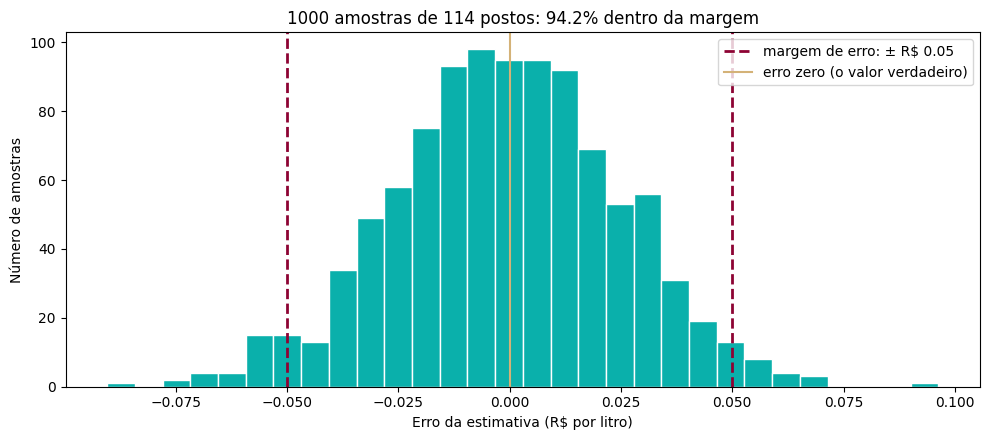

O que fica fora das linhas tracejadas é o que a confiança admite errar.


In [9]:
# O gráfico da verificação: o erro de cada amostra, com a margem marcada.
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(erros, bins=30, color="#0AB0AB", edgecolor="white")
ax.axvline(-MARGEM, color="#8D0333", linewidth=2, linestyle="--")
ax.axvline(MARGEM, color="#8D0333", linewidth=2, linestyle="--",
           label=f"margem de erro: ± R$ {MARGEM:.2f}")
ax.axvline(0, color="#D4B277", linewidth=1.5, label="erro zero (o valor verdadeiro)")
ax.set_xlabel("Erro da estimativa (R$ por litro)")
ax.set_ylabel("Número de amostras")
ax.set_title(f"{N_VEZES} amostras de {n_media_final} postos: {dentro:.1f}% dentro da margem")
ax.legend()
plt.tight_layout()
plt.show()

print("O que fica fora das linhas tracejadas é o que a confiança admite errar.")

**A frase que vai para o relatório**

> "Para estimar o preço médio da gasolina comum nos postos do Maranhão com margem de erro de
> **R\$ 0,05** e **95% de confiança**, sorteiam-se **114 dos 236 postos** do cadastro da ANP
> (desvio padrão de R\$ 0,38; tamanho calculado com correção para população finita). Em
> 1.000 sorteios simulados, **94,2%** das estimativas ficaram dentro da margem (ANP, SHPC,
> 2025)."

**O que essa frase não diz.** Que a estimativa vai errar menos de R\$ 0,05 com certeza. Cerca
de 1 amostra em 20 erra mais que isso, e é o que os 95% admitem. E ela não diz nada sobre
**viés**: se o sorteio for trocado por conveniência, a margem calculada deixa de valer.

### 5. O tamanho da amostra para uma proporção e o tamanho da população

Para uma proporção (que parte das empresas exporta? que parte dos municípios tem sala do
empreendedor?) a fórmula usa **p = 0,5** quando não se sabe nada antes: é o valor que exige
o maior n e por isso é o **conservador**.

In [10]:
# O tamanho da amostra para estimar uma PROPORÇÃO, com p = 0,5 (o caso conservador).
P = 0.5
n0_prop = z ** 2 * P * (1 - P) / MARGEM_PROP ** 2
n_prop = n0_prop / (1 + (n0_prop - 1) / N_POPULACAO)

print(f"Pergunta: estimar uma proporção com margem de {MARGEM_PROP * 100:.0f} p.p., "
      f"a {CONFIANCA:.0%}, com p = 0,5")
print(f"  sem correção: n0 = {z:.3f}² × 0,5 × 0,5 ÷ {MARGEM_PROP}² = {n0_prop:.1f}"
      f"  →  {int(np.ceil(n0_prop))}")
print(f"  para um cadastro de N = {N_POPULACAO}: n = {n_prop:.1f}  →  {int(np.ceil(n_prop))}")
print()

# o mesmo cálculo para quatro cadastros reais, do menor ao maior
cadastros = pd.DataFrame({
    "cadastro": ["Postos de gasolina do MA (ANP)",
                 "Municípios do Brasil (Receita Federal)",
                 "Empresas do Maranhão (CEMPRE 2024)",
                 "Empresas do Brasil (CEMPRE 2024)"],
    "N": [N, len(municipios), 168098, 10607110],
})
cadastros["n necessário"] = np.ceil(n0_prop / (1 + (n0_prop - 1) / cadastros["N"])).astype(int)
cadastros["% do cadastro"] = (cadastros["n necessário"] / cadastros["N"] * 100).round(3)
print(cadastros.to_string(index=False))
print()
print(f"O cadastro cresce {cadastros['N'].iloc[-1] / cadastros['N'].iloc[0]:,.0f} vezes; "
      f"o n necessário cresce {cadastros['n necessário'].iloc[-1] / cadastros['n necessário'].iloc[0]:.1f} vezes."
      .replace(",", "."))
print("A partir de alguns milhares, o tamanho da população quase não importa.")
print()
conferir("n sem correção (proporção, ±5 p.p., 95%)", np.ceil(n0_prop), 385,
         tolerancia=0, unidade=" casos")
conferir("n para o cadastro da Receita (N = 5.572)", np.ceil(n_prop), 360,
         tolerancia=0, unidade=" munic.")

Pergunta: estimar uma proporção com margem de 5 p.p., a 95%, com p = 0,5
  sem correção: n0 = 1.960² × 0,5 × 0,5 ÷ 0.05² = 384.1  →  385
  para um cadastro de N = 5572: n = 359.4  →  360

                              cadastro        N  n necessário  % do cadastro
        Postos de gasolina do MA (ANP)      236           147         62.288
Municípios do Brasil (Receita Federal)     5572           360          6.461
    Empresas do Maranhão (CEMPRE 2024)   168098           384          0.228
      Empresas do Brasil (CEMPRE 2024) 10607110           385          0.004

O cadastro cresce 44.945 vezes; o n necessário cresce 2.6 vezes.
A partir de alguns milhares, o tamanho da população quase não importa.

  [ok] n sem correção (proporção, ±5 p.p., 95%)               obtido 385.00 casos esperado 385.00 casos
  [ok] n para o cadastro da Receita (N = 5.572)               obtido 360.00 munic. esperado 360.00 munic.


In [11]:
# A verificação da proporção, no cadastro em que a resposta é conhecida:
# a proporção de postos de bandeira branca (sem marca de distribuidora).
branca = (cadastro["bandeira"] == "BRANCA")
p_verdadeiro = branca.mean()
n_branca = int(np.ceil(n0_prop / (1 + (n0_prop - 1) / N)))

proporcoes = np.array([branca.sample(n=n_branca, random_state=k).mean()
                       for k in range(N_VEZES)])
dentro_prop = (np.abs(proporcoes - p_verdadeiro) <= MARGEM_PROP).mean() * 100

print(f"Postos de bandeira branca: {branca.sum()} de {N} = {p_verdadeiro:.1%} (o valor verdadeiro)")
print(f"n para ±{MARGEM_PROP * 100:.0f} p.p. num cadastro de {N}: {n_branca} postos")
print(f"Das {N_VEZES} amostras de {n_branca}: {dentro_prop:.1f}% ficaram a menos de "
      f"{MARGEM_PROP * 100:.0f} p.p. do valor verdadeiro")
print()
conferir("postos de bandeira branca no cadastro", p_verdadeiro * 100, 50.4,
         tolerancia=0.05, unidade="%")
conferir("n para a proporção, N = 236", n_branca, 147, tolerancia=0, unidade=" postos")
conferir("amostras dentro de ±5 p.p. (simulação)", dentro_prop, 96.0,
         tolerancia=0.05, unidade="%")

Postos de bandeira branca: 119 de 236 = 50.4% (o valor verdadeiro)
n para ±5 p.p. num cadastro de 236: 147 postos
Das 1000 amostras de 147: 96.0% ficaram a menos de 5 p.p. do valor verdadeiro

  [ok] postos de bandeira branca no cadastro                  obtido 50.42%    esperado 50.40%
  [ok] n para a proporção, N = 236                            obtido 147.00 postos esperado 147.00 postos
  [ok] amostras dentro de ±5 p.p. (simulação)                 obtido 96.00%    esperado 96.00%


> **Dica de estudo**: no cadastro da ANP, metade dos postos é de bandeira branca: o p verdadeiro é exatamente 0,5, o caso conservador. Com p = 0,5 e N = 236, a fórmula sem correção pediria 385 postos, mais do que o cadastro tem; a correção reduz para 147.

## Seção 3. A escala Likert e o alfa de Cronbach

> **ATENÇÃO: as respostas desta seção são SIMULADAS.** Não vêm de nenhuma pesquisa real.
> Foram geradas por código, com **semente fixa (2026)**, para que todos vejam os mesmos
> números e para que se saiba de antemão o que a escala deveria medir.

**O instrumento.** 200 gestores responderam a seis afirmações sobre um fornecedor, numa
escala Likert de 5 pontos (1 = discordo totalmente; 5 = concordo totalmente):

| Item | Afirmação | Coluna |
|---|---|---|
| 1 | O fornecedor entrega no prazo combinado | `prazo` |
| 2 | A qualidade dos produtos atende ao que foi contratado | `qualidade` |
| 3 | O fornecedor resolve rapidamente os problemas que aparecem | `solucao` |
| 4 | A comunicação com o fornecedor é clara | `comunicacao` |
| 5 | Eu recomendaria este fornecedor a outra empresa | `recomendaria` |
| 6 | **Tenho problemas frequentes com este fornecedor** | `problemas` |

O item 6 é **redigido ao contrário**: concordar com ele indica **menos** satisfação. Antes de
somar os itens, ele precisa ser **recodificado** (5 vira 1, 4 vira 2, e assim por diante).

$$\alpha = \frac{k}{k-1}\left(1 - \frac{\sum s^2_{item}}{s^2_{total}}\right)
\qquad\qquad
\alpha_{padronizado} = \frac{k \times \bar{r}}{1 + (k-1) \times \bar{r}}$$

* $k$ é o número de itens; $\bar{r}$ é a correlação média entre os itens
* $s^2_{item}$ é a variância de cada item; $s^2_{total}$ é a variância da soma dos itens

**Em linguagem corrente:** o alfa sobe quando os itens andam juntos (r̄ alto) **e** quando
há mais itens (k alto). É por isso que um alfa alto não prova, sozinho, que a escala mede o
que diz medir.

In [12]:
# ============ RESPOSTAS SIMULADAS: não são dados reais ============
rng = np.random.default_rng(2026)            # semente fixa: todos veem os mesmos números
N_RESP = 200
satisfacao = rng.normal(0, 1, N_RESP)        # a satisfação "verdadeira" de cada gestor
cargas = np.array([0.75, 0.70, 0.70, 0.65, 0.75, 0.70])
ruido = rng.normal(0, 1, (N_RESP, 6))
latente = satisfacao[:, None] * cargas + ruido * np.sqrt(1 - cargas ** 2)
respostas = np.clip(np.round(3 + 1.2 * latente), 1, 5).astype(int)
respostas[:, 5] = 6 - respostas[:, 5]         # o item 6 foi redigido ao contrário

itens = pd.DataFrame(respostas, columns=["prazo", "qualidade", "solucao",
                                         "comunicacao", "recomendaria", "problemas"])
print(f"Respostas SIMULADAS: {len(itens)} gestores x {itens.shape[1]} itens")
print()
print("As cinco primeiras respostas:")
print(itens.head().to_string())
print()

# a frequência de um item: Likert é ordinal, e a tabela respeita a ordem (encontro 2)
freq = itens["prazo"].value_counts().sort_index()
tabela = pd.DataFrame({"respostas": freq, "%": (freq / len(itens) * 100).round(1)})
tabela.index.name = "prazo (1 a 5)"
print(tabela.to_string())
print()
conferir("respostas simuladas", len(itens), 200, tolerancia=0, unidade=" resp.")

Respostas SIMULADAS: 200 gestores x 6 itens

As cinco primeiras respostas:
   prazo  qualidade  solucao  comunicacao  recomendaria  problemas
0      2          3        2            3             2          3
1      3          4        4            3             3          2
2      2          1        1            2             1          5
3      3          3        3            4             4          2
4      4          3        3            3             3          3

               respostas     %
prazo (1 a 5)                 
1                     19   9.5
2                     43  21.5
3                     70  35.0
4                     44  22.0
5                     24  12.0

  [ok] respostas simuladas                                    obtido 200.00 resp. esperado 200.00 resp.


In [13]:
# O alfa de Cronbach, antes e depois de recodificar o item invertido.
k = itens.shape[1]

print("Correlação do item 'problemas' com os demais, ANTES de recodificar:")
print(itens.corr()["problemas"].drop("problemas").round(2).to_string())
print("Todas negativas: o item mede a mesma coisa, mas ao contrário.")
print()

alfa_errado = k / (k - 1) * (1 - itens.var().sum() / itens.sum(axis=1).var())

itens_ok = itens.copy()
itens_ok["problemas"] = 6 - itens_ok["problemas"]      # recodifica: 5→1, 4→2, ..., 1→5
alfa = k / (k - 1) * (1 - itens_ok.var().sum() / itens_ok.sum(axis=1).var())

print(f"alfa com o item 6 SEM recodificar ... {alfa_errado:.3f}   (abaixo do piso de 0,7)")
print(f"alfa com o item 6 recodificado ...... {alfa:.3f}")
print()
conferir("alfa sem recodificar o item 6", alfa_errado, 0.561, tolerancia=0.001, unidade="")
conferir("alfa com o item 6 recodificado", alfa, 0.857, tolerancia=0.001, unidade="")

Correlação do item 'problemas' com os demais, ANTES de recodificar:
prazo          -0.48
qualidade      -0.44
solucao        -0.45
comunicacao    -0.42
recomendaria   -0.53
Todas negativas: o item mede a mesma coisa, mas ao contrário.

alfa com o item 6 SEM recodificar ... 0.561   (abaixo do piso de 0,7)
alfa com o item 6 recodificado ...... 0.857

  [ok] alfa sem recodificar o item 6                          obtido 0.5607    esperado 0.5610
  [ok] alfa com o item 6 recodificado                         obtido 0.8574    esperado 0.8570


In [14]:
# O alfa como função do número de itens (k) e da correlação média entre eles (r̄).
correlacoes = itens_ok.corr().values
r_medio = correlacoes[np.triu_indices(k, 1)].mean()    # média das 15 correlações entre pares
alfa_padronizado = k * r_medio / (1 + (k - 1) * r_medio)

print(f"correlação média entre os itens (r̄) ..... {r_medio:.3f}")
print(f"alfa padronizado: 6 × r̄ ÷ (1 + 5 × r̄) ... {alfa_padronizado:.3f}"
      f"   (o alfa das variâncias deu {alfa:.3f})")
print()

ks = np.arange(2, 13)
tabela_alfa = pd.DataFrame({"itens (k)": ks,
                            "alfa com o mesmo r̄": (ks * r_medio / (1 + (ks - 1) * r_medio)).round(3)})
print(tabela_alfa.to_string(index=False))
print()
print("Com a MESMA correlação média, só acrescentar itens empurra o alfa para cima.")
print("Alfa alto mede consistência, e não prova que a escala mede satisfação.")
print()
conferir("correlação média entre os itens", r_medio, 0.501, tolerancia=0.001, unidade="")
conferir("alfa padronizado (k = 6)", alfa_padronizado, 0.858, tolerancia=0.001, unidade="")
conferir("alfa previsto com 12 itens", tabela_alfa.iloc[-1, 1], 0.923, tolerancia=0.001,
         unidade="")

correlação média entre os itens (r̄) ..... 0.501
alfa padronizado: 6 × r̄ ÷ (1 + 5 × r̄) ... 0.858   (o alfa das variâncias deu 0.857)

 itens (k)  alfa com o mesmo r̄
         2                0.668
         3                0.751
         4                0.801
         5                0.834
         6                0.858
         7                0.876
         8                0.889
         9                0.900
        10                0.910
        11                0.917
        12                0.923

Com a MESMA correlação média, só acrescentar itens empurra o alfa para cima.
Alfa alto mede consistência, e não prova que a escala mede satisfação.

  [ok] correlação média entre os itens                        obtido 0.5014    esperado 0.5010
  [ok] alfa padronizado (k = 6)                               obtido 0.8578    esperado 0.8580
  [ok] alfa previsto com 12 itens                             obtido 0.9230    esperado 0.9230


**A frase que vai para o relatório**

> "A escala de satisfação com o fornecedor, com seis itens Likert de 5 pontos (o item 6
> recodificado), apresentou **alfa de Cronbach de 0,857** em 200 respondentes, acima do piso
> usual de 0,7. *(Dados simulados, para fins didáticos.)*"

**O que essa frase não diz.** Que a escala é **válida**. O alfa mede **confiabilidade**, isto é, se
os itens andam juntos. Se a escala medir, com muita consistência, outra coisa que não a
satisfação, o alfa continua alto.

## Seção 4. As três perguntas do dia

Responda por escrito, editando as células abaixo.

**1. O simulador.** Volte ao bloco de configuração, mude `MARGEM` de `0.05` para `0.03`
e execute o notebook de novo. Quantos postos a fórmula pede agora? A simulação confirmou que
a margem se cumpre? Escreva a frase do relatório com o novo número.

---


**2. O tamanho da população.** Por que o n necessário para um cadastro de 168 mil empresas é
praticamente igual ao de um cadastro de 10,6 milhões? E por que a regra “amostra de 10% da
população” não faz sentido?

---


**3. O seu projeto.** Se o seu projeto coletasse dados primários (um questionário com
gestores, por exemplo): o que o TCLE teria de dizer, e qual dado pessoal você deixaria de
coletar para respeitar a minimização da LGPD?

---


## Antes de sair

- [ ] Executei o notebook inteiro de cima para baixo, sem erro
- [ ] Mudei `MARGEM` e `CONFIANCA` e vi o n mudar, e a simulação conferir a margem
- [ ] Sei dizer a diferença entre erro aleatório (diminui com n) e viés (não diminui)
- [ ] Sei por que o alfa subiu de 0,561 para 0,857 depois de recodificar o item 6
- [ ] Respondi as três perguntas, uma delas sobre o meu projeto

> **O próximo encontro é a AV2**, sobre os Módulos I e II: descrição completa de uma base,
> plano de amostragem e tamanho da amostra calculado, que é o que este notebook e os
> dos encontros 6 e 7 fizeram. Traga o seu sorteio do encontro 6 salvo: ele vira o
> **relatório de sorteio**.